# PyDoppler tutorial

This notebook walks through a complete Doppler tomography analysis with
**PyDoppler 1.0**, using the U Gem test dataset that ships with the package.

Doppler tomography turns a time series of emission-line profiles, taken at
different orbital phases, into a map of the emission in velocity space
$(V_x, V_y)$. Each point in the map traces a sinusoid in the trail spectrum,

$$ v_{\rm los}(\phi) = \gamma - V_x \cos 2\pi\phi + V_y \sin 2\pi\phi , $$

and PyDoppler finds the smoothest (maximum-entropy) map whose projections
reproduce the observed spectra, following Spruit (1998).

**Steps**

1. Install and load the test data
2. Set up the `spruit` object
3. Read the spectra (`Foldspec`)
4. Normalise the spectra and build the trail (`Dopin`)
5. Compute the tomogram (`Syncdop`)
6. Plot the map (`Dopmap`) and overplot the binary geometry (`stream`)
7. Check the reconstruction (`Reco`)
8. Tune the reconstruction and access the results
9. Use your own data

Everything runs in Python, with no Fortran compiler needed. The full run
takes a few seconds.

## 1. Installation and test data

Install from PyPI (once):

```
pip install pydoppler
```

`pydoppler.test_data()` copies the U Gem spectra (folder `ugem99/`) and a
ready-to-run `sample_script.py` into the **current working directory**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydoppler

print("PyDoppler version:", pydoppler.__version__)
pydoppler.test_data()

PyDoppler version: 1.0.0
  ✓  Test data copied to current directory.


### Input data format

* **One file per spectrum**, two space-separated columns: wavelength (Å) and
  flux. No header, or comment lines starting with `#`.
* **A phase file** listing each spectrum file and its orbital phase (a third
  column is allowed and ignored):

```
txhugem4004  0.7150
txhugem4005  0.7794
...
```

The test data was published in Echevarria et al. (2007, AJ, 134, 262).

In [2]:
with open("ugem99/ugem0all.fas") as f:
    print("".join(f.readlines()[:5]))

w, fl = np.loadtxt("ugem99/txhugem4004", unpack=True)
print(f"{w.size} pixels, {w.min():.1f} - {w.max():.1f} Å")

txhugem4004  0.7150 0.03930
txhugem4005  0.7794 0.03930
txhugem4006  0.8348 0.03930
txhugem4007  0.8942 0.03930
txhugem4008  0.9518 0.03930

2048 pixels, 6425.7 - 6726.3 Å


## 2. Set up the `spruit` object

All inputs and settings live on a `pydoppler.spruit` object. The essential
ones describe the data and the velocity window of the map:

| Attribute | Meaning |
|---|---|
| `object` | Target name (used in plot titles) |
| `base_dir` | Folder containing the spectra and the phase file |
| `list` | Name of the phase file |
| `lam0` | Rest wavelength of the line, in the units of the spectra (Å) |
| `delw` | Half-width of the wavelength window around `lam0` (Å) |
| `gama` | Systemic velocity $\gamma$ (km/s), removed before mapping |
| `delta_phase` | Exposure length in units of orbital phase |
| `overs` | Map oversampling (0-1); sets the map size from the data resolution |
| `nbins` | Number of phase bins for the trail plots |

In [3]:
dop = pydoppler.spruit()

dop.object      = 'U Gem'
dop.base_dir    = 'ugem99'
dop.list        = 'ugem0all.fas'
dop.lam0        = 6562.8      # H-alpha
dop.delw        = 35          # +/- 35 Å around lam0
dop.gama        = 36.0        # km/s
dop.delta_phase = 0.003
dop.overs       = 0.3
dop.nbins       = 28

## 3. Read the spectra: `Foldspec`

Reads every spectrum listed in the phase file, together with its phase.

In [4]:
dop.Foldspec()


────────────────────────────────────────────────────────────
  Foldspec — reading & phase-binning spectra
────────────────────────────────────────────────────────────
  →  Found 28 spectra in ugem99/ugem0all.fas
  →  Phase bins: 28

  [█░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   3%  txhugem4004  φ=0.7150  npix=2048

  [██░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   7%  txhugem4005  φ=0.7794  npix=2048

  [███░░░░░░░░░░░░░░░░░░░░░░░░░░░]  10%  txhugem4006  φ=0.8348  npix=2048

  [████░░░░░░░░░░░░░░░░░░░░░░░░░░]  14%  txhugem4007  φ=0.8942  npix=2048

  [█████░░░░░░░░░░░░░░░░░░░░░░░░░]  17%  txhugem4008  φ=0.9518  npix=2048

  [██████░░░░░░░░░░░░░░░░░░░░░░░░]  21%  txhugem4009  φ=0.0072  npix=2048

... (19 outputs left out)

  [███████████████████████████░░░]  92%  txhugem4029  φ=0.0648  npix=2048

  [████████████████████████████░░]  96%  txhugem4030  φ=0.1027  npix=2048

  [██████████████████████████████] 100%  txhugem4031  φ=0.1372  npix=2048


  ✓  Loaded 28 spectra, 2048 pixels each


## 4. Normalise the spectra: `Dopin`

`Dopin` fits the continuum in two bands, one on each side of the line, given
as `[blue_start, blue_end, red_start, red_end]` in Å. It subtracts the fit,
converts wavelength to velocity, and resamples all spectra onto a common
velocity grid.

Pick bands that are free of line emission. The top panel of the figure shows
the bands and the fit, and the bottom panel shows the continuum-subtracted
average profile with the velocity range of the map.

Outputs saved: `Average_Spec.png` and `Trail.png`.


────────────────────────────────────────────────────────────
  Dopin — continuum normalisation
────────────────────────────────────────────────────────────


  ✓  Continuum plot saved → Average_Spec.png

  [█░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   3%  spectrum 1/28

  [██░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   7%  spectrum 2/28

  [███░░░░░░░░░░░░░░░░░░░░░░░░░░░]  10%  spectrum 3/28

  [████░░░░░░░░░░░░░░░░░░░░░░░░░░]  14%  spectrum 4/28

  [█████░░░░░░░░░░░░░░░░░░░░░░░░░]  17%  spectrum 5/28

... (21 outputs left out)

  [████████████████████████████░░]  96%  spectrum 27/28

  [██████████████████████████████] 100%  spectrum 28/28


  ✓  Velocity range: -1598.9 → 1593.2 km/s  (477 pixels)


  ✓  Trail spectrum saved → Trail.png


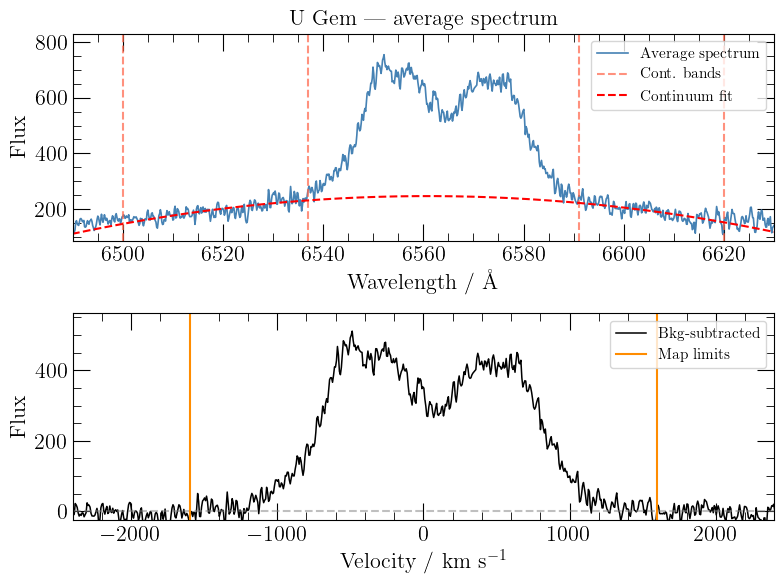

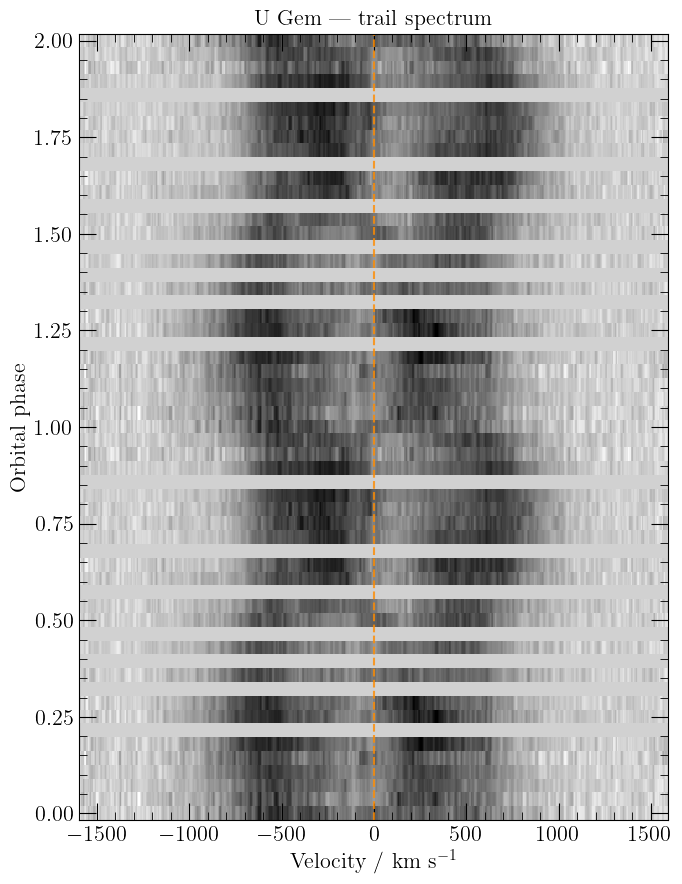

In [5]:
dop.Dopin(continnum_band=[6500, 6537, 6591, 6620],
          plot_median=False, poly_degree=2)

The trail spectrum shows the double-peaked disc profile and an S-wave
moving with orbital phase. Horizontal gaps are phase bins without spectra.

## 5. Compute the tomogram: `Syncdop`

`Syncdop` runs the maximum-entropy (MEM) reconstruction. It iterates a
Lucy-accelerated Richardson-Lucy scheme at a regularisation weight $\alpha$,
then lowers $\alpha$ by a factor `alf` until the reduced $\chi$ between data
and reconstruction reaches `clim`.

| Attribute | Default | Meaning |
|---|---|---|
| `nim` | 150 | Maximum iterations per $\alpha$ |
| `nal` | 0 | Maximum number of $\alpha$ values (0 = a single $\alpha$) |
| `al0` | 0.002 | Starting $\alpha$ |
| `alf` | 1.7 | Factor between successive $\alpha$ values |
| `clim` | 1.6 | Target reduced $\chi$ |
| `ac` | 8e-4 | Convergence accuracy at each $\alpha$ |
| `ns` | 7 | Width (pixels) of the Gaussian default map |
| `pb0`, `pb1` | 0.95, 1.05 | Phase range to ignore (e.g. eclipse) |
| `norm` | 1 | Normalise each spectrum to the same integrated flux |
| `ih` | 0 | Likelihood: 0 = log-likelihood, 1 = $\chi^2$ |

A larger $\alpha$ gives a smoother map, and a smaller $\alpha$ fits the
noise more closely. Stop at a $\chi$ consistent with the data, not as low as
possible.

In [6]:
dop.nim  = 150
dop.nal  = 10
dop.clim = 1.6
dop.al0  = 2e-3
dop.ns   = 7

dop.Syncdop()          # map size set from dop.overs; or dop.Syncdop(nv=100)


────────────────────────────────────────────────────────────
  Syncdop — MEM Doppler tomography  (native Python)
────────────────────────────────────────────────────────────
  →  Map grid:    144 × 144 pixels
  →  Input data:  28 phases × 477 velocity channels
  →  Projection matrix: sparse, ~29 MB

  Alpha step           α     nit         χ    target
  ──────────  ──────────  ──────  ────────  ────────


  ✓  α=2.00e-03  nit=  28  χ=1.5233  (target ≤ 1.60)

  ✓  Converged!  χ = 1.5233  (target ≤ 1.60)  [0.8 s]
  →  Final α = 2.00e-03   iterations = 28
  →  Entropy S = -2.5016e+04


## 6. Plot the map: `Dopmap` and `stream`

`Dopmap` displays the tomogram and saves `Doppler_Map.png`. Useful options:

* `stretch='linear'` (default), `'sqrt'` or `'log'`. The last two bring out
  faint structure next to bright features.
* `cmaps=plt.cm.magma_r` (default) or any matplotlib colour map
* `limits=[lo, hi]` for the colour range of the stretched image (0-1), or
  `percentile_lo` / `percentile_hi` for clipping
* `smooth=True` for interpolated display
* `colorbar=True/False`

`pydoppler.stream(q, K1, Porb, M1, inc)` overplots the donor's Roche lobe,
the ballistic gas stream (solid) and the Keplerian velocity along it (dashed),
and the white dwarf (+) and centre-of-mass (x) velocities. Optional circles
show the tidal radius and the 3:2 and 2:1 resonances. Call it in the **same
cell** as `Dopmap` so it draws on the same axes.


────────────────────────────────────────────────────────────
  Dopmap — velocity map
────────────────────────────────────────────────────────────
  →  Velocity range:  -1599 → 1599 km/s  (144×144 pixels)
  →  Stretch:         linear
  →  Colour limits:   [0.000, 1.000]  (data clipped at p2–p99.5)


  ✓  Doppler map saved → Doppler_Map.png


  →  Tidal radius:    r/a = 0.444   v_Kep = 627.7 km/s  (at WD)
  →  3:2 resonance:   r/a = 0.435   v_Kep = 634.5 km/s
  →  2:1 resonance:   r/a = 0.570   v_Kep = 554.3 km/s


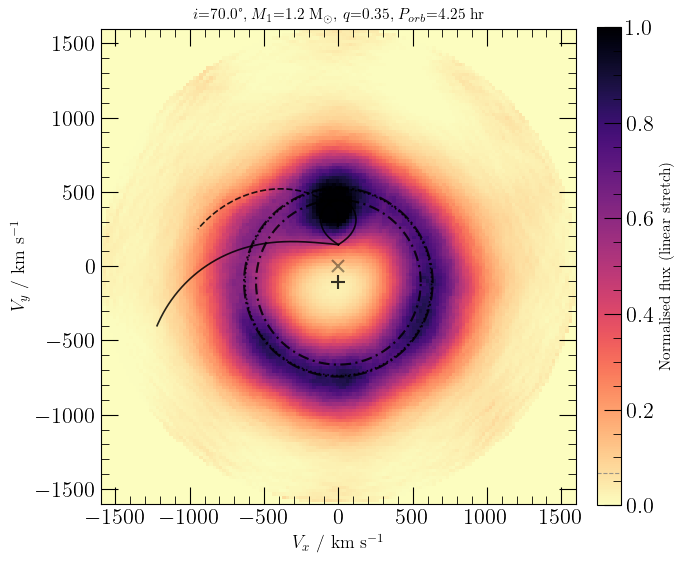

In [7]:
fig, data = dop.Dopmap(colorbar=True)

q    = 0.35            # mass ratio M2/M1
k1   = 107             # K1, km/s
porb = 0.1769061911    # orbital period, days
m1   = 1.2             # M1, solar masses
inc  = 70              # inclination, degrees

pydoppler.stream(q, k1, porb, m1, inc,
                 tidal_radius=True, resonance_32=True, resonance_21=True)
plt.savefig('Doppler_Map_with_stream.pdf', bbox_inches='tight')

The map shows the accretion-disc ring between the tidal-radius and resonance
circles, and strong emission on the donor star's Roche lobe at
$(0, +K_2)$, typical of an irradiated secondary.

The same map with a square-root stretch and a dark colour map. Use white
stream lines on dark backgrounds:


────────────────────────────────────────────────────────────
  Dopmap — velocity map
────────────────────────────────────────────────────────────
  →  Velocity range:  -1599 → 1599 km/s  (144×144 pixels)
  →  Stretch:         sqrt
  →  Colour limits:   [0.000, 1.000]  (data clipped at p2–p99.5)


  ✓  Doppler map saved → Doppler_Map.png


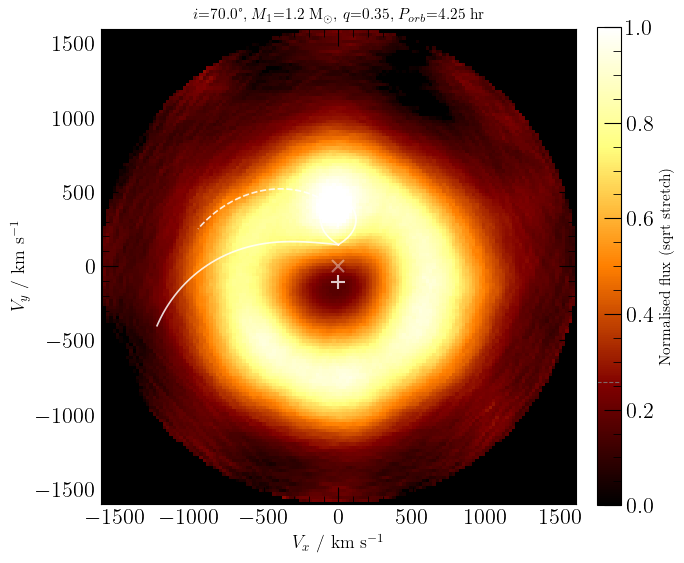

In [8]:
fig, data = dop.Dopmap(stretch='sqrt', cmaps=plt.cm.afmhot, colorbar=True)
pydoppler.stream(q, k1, porb, m1, inc, colors='white')

## 7. Check the reconstruction: `Reco`

Always compare the reconstructed trail with the data. A good rule of thumb:
*if a feature in the tomogram is not in the trail spectrum, it is most likely
not real.*

`Reco` returns the figure and the input and reconstructed spectra
(phase × velocity, baseline removed), and saves `Reconstruction.png`.


────────────────────────────────────────────────────────────
  Reco — reconstructed trail spectra
────────────────────────────────────────────────────────────


  ✓  Reconstruction plot saved → Reconstruction.png
input: (28, 477)  reconstruction: (28, 477)


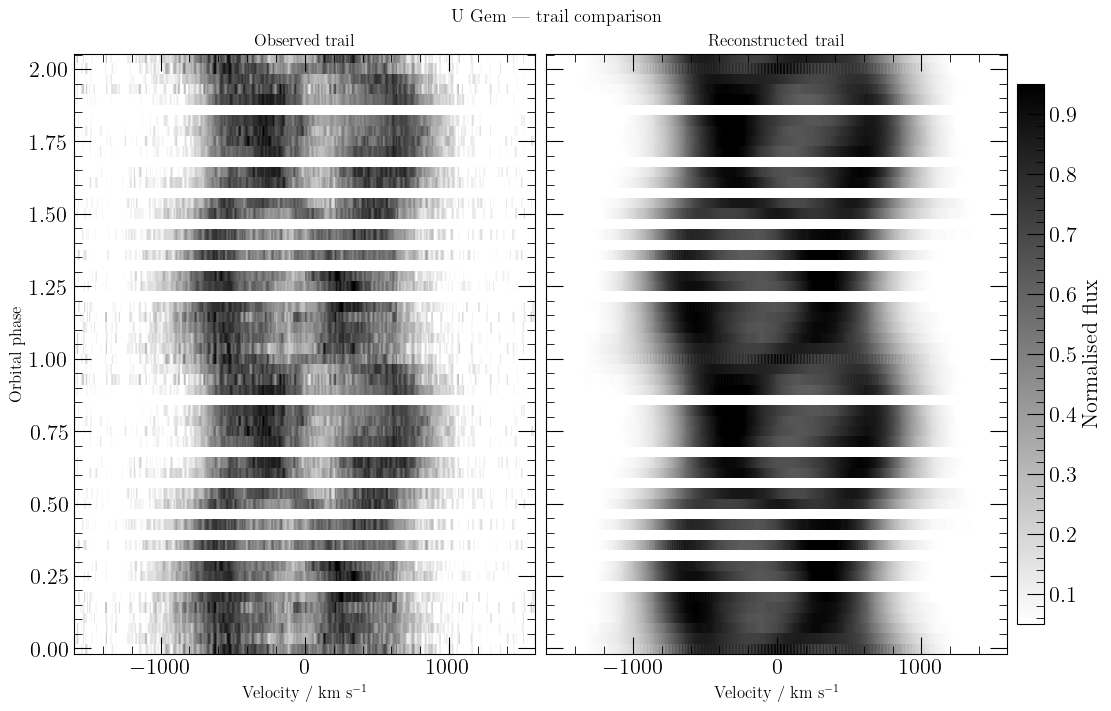

In [9]:
fig, dm, dmr = dop.Reco(colorbar=True, limits=[0.05, 0.95])
print("input:", dm.shape, " reconstruction:", dmr.shape)

## 8. Tuning and accessing the results

After `Syncdop`, the full result is stored in `dop._mem_result`:

| Field | Content |
|---|---|
| `image` | 2-D map, `nv × nv` (rows: $V_y$, columns: $V_x$ when plotted) |
| `va` | Half-width of the velocity grid (km/s) |
| `chi2`, `alpha` | Final reduced $\chi$ and regularisation weight |
| `converged`, `n_iter` | Convergence flag and iterations at the last $\alpha$ |
| `dm`, `dm_reco` | Input and reconstructed spectra |

In [10]:
r = dop._mem_result
print(f"map {r.image.shape}, va = {r.va:.0f} km/s, chi = {r.chi2:.3f}, "
      f"alpha = {r.alpha:.2e}, converged = {r.converged}")

# residuals in units of the data scatter
resid = r.dm - r.dm_reco
print(f"rms residual / rms data = {resid.std() / r.dm.std():.3f}")

map (144, 144), va = 1599 km/s, chi = 1.523, alpha = 2.00e-03, converged = True
rms residual / rms data = 0.323


**Lowering the target $\chi$** with `clim` makes PyDoppler step down in
$\alpha$ until the target is met, or until `nal` steps have been used. Here
the data allow $\chi \approx 1.45$. Below the noise floor (about 1.42 for
this dataset), the fit stops improving and the run reports that it did not
converge.


────────────────────────────────────────────────────────────
  Syncdop — MEM Doppler tomography  (native Python)
────────────────────────────────────────────────────────────
  →  Map grid:    144 × 144 pixels
  →  Input data:  28 phases × 477 velocity channels
  →  Projection matrix: sparse, ~29 MB

  Alpha step           α     nit         χ    target
  ──────────  ──────────  ──────  ────────  ────────


  →  α=2.00e-03  nit=  28  χ=1.5233  (target ≤ 1.45)


  →  α=1.18e-03  nit=  28  χ=1.4824  (target ≤ 1.45)


  →  α=7.65e-04  nit=  27  χ=1.4583  (target ≤ 1.45)


  ✓  α=5.75e-04  nit=  23  χ=1.4464  (target ≤ 1.45)

  ✓  Converged!  χ = 1.4464  (target ≤ 1.45)  [1.6 s]
  →  Final α = 5.75e-04   iterations = 23
  →  Entropy S = -6.7705e+04

────────────────────────────────────────────────────────────
  Dopmap — velocity map
────────────────────────────────────────────────────────────
  →  Velocity range:  -1599 → 1599 km/s  (144×144 pixels)
  →  Stretch:         linear
  →  Colour limits:   [0.000, 1.000]  (data clipped at p2–p99.5)


  ✓  Doppler map saved → Doppler_Map.png


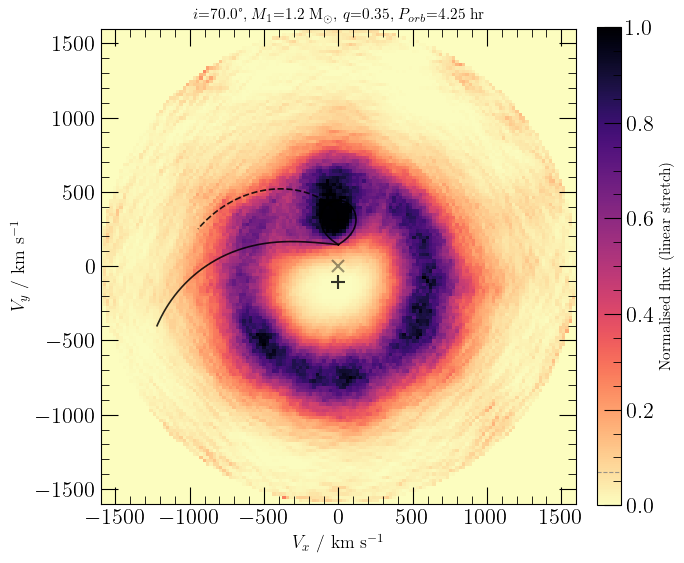

In [11]:
dop.clim = 1.45
dop.Syncdop()
fig, data = dop.Dopmap(colorbar=True)
pydoppler.stream(q, k1, porb, m1, inc)

**Map resolution:** pass `nv` to `Syncdop` to set the number of pixels per
side, for example `dop.Syncdop(nv=100)` for a quicker, coarser map.


────────────────────────────────────────────────────────────
  Syncdop — MEM Doppler tomography  (native Python)
────────────────────────────────────────────────────────────
  →  Map grid:    100 × 100 pixels
  →  Input data:  28 phases × 477 velocity channels
  →  Projection matrix: sparse, ~17 MB

  Alpha step           α     nit         χ    target
  ──────────  ──────────  ──────  ────────  ────────


  →  α=2.00e-03  nit=  18  χ=1.6693  (target ≤ 1.60)
  ✓  α=1.18e-03  nit=  18  χ=1.5866  (target ≤ 1.60)

  ✓  Converged!  χ = 1.5866  (target ≤ 1.60)  [0.5 s]
  →  Final α = 1.18e-03   iterations = 18
  →  Entropy S = -5.6552e+04

────────────────────────────────────────────────────────────
  Dopmap — velocity map
────────────────────────────────────────────────────────────
  →  Velocity range:  -1599 → 1599 km/s  (100×100 pixels)
  →  Stretch:         linear
  →  Colour limits:   [0.000, 1.000]  (data clipped at p2–p99.5)


  ✓  Doppler map saved → Doppler_Map.png


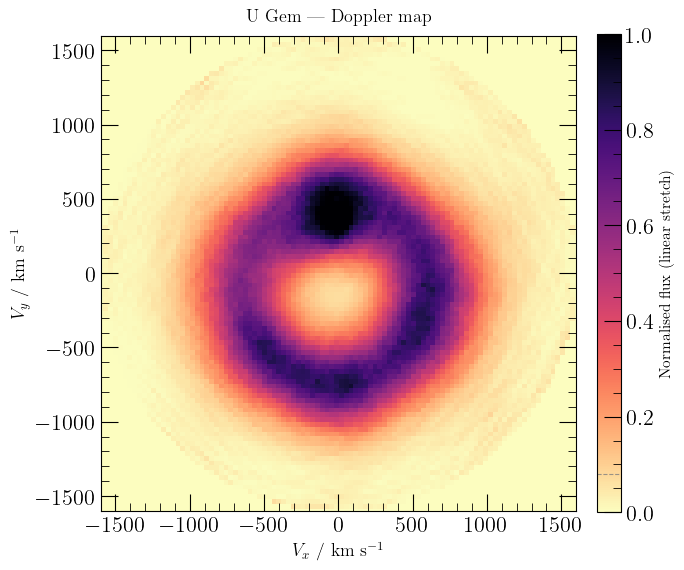

In [12]:
dop.clim = 1.6
dop.Syncdop(nv=100)
fig, data = dop.Dopmap(colorbar=True)

## 9. Using your own data

Organise your data as

```
wrk_dir
└── data_dir
    ├── spectrum_001 ... spectrum_N   (wavelength  flux)
    └── phases.txt                    (spectrum_name  phase)
```

and adapt this template:

```python
import pydoppler
import matplotlib.pyplot as plt

dop = pydoppler.spruit()
dop.object      = 'My CV'
dop.base_dir    = 'data_dir'
dop.list        = 'phases.txt'
dop.lam0        = 6562.8          # line rest wavelength (Å)
dop.delw        = 40              # half-window (Å)
dop.gama        = 0.0             # systemic velocity (km/s)
dop.delta_phase = 0.01            # exposure length / orbital period
dop.nbins       = 20

dop.Foldspec()
dop.Dopin(continnum_band=[6490, 6530, 6600, 6640])
dop.Syncdop()
fig, data = dop.Dopmap()
pydoppler.stream(q, k1, porb, m1, inc)
fig, dm, dmr = dop.Reco()
```

### Citation

If you use PyDoppler, please cite Spruit (1998, astro-ph/9806141) and
Hernandez Santisteban (2021, ASCL 2106.003).